In [1]:

%pip install -q pandas numpy scikit-learn xgboost optuna matplotlib joblib

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import xgboost
import optuna
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
N_TRIALS = 20

LABELS = ["Low", "Mid", "High"]
LABEL_MAP = {"Low": 0, "Mid": 1, "High": 2}

BASIC = [
    "Age", "BodyTemp", "HeartRate",
    "SystolicBP", "DiastolicBP", "BMI"
]
FULL = BASIC + ["HbA1c", "FastingGlucose"]

FAMILIES = ["LR", "DT", "RF", "SVM", "XGB"]

if (Path.cwd() / "splits/train.csv").exists():
    BASE = Path.cwd()
elif (Path.cwd() / "output/splits/train.csv").exists():
    BASE = Path.cwd() / "output"
else:
    raise FileNotFoundError(
        "Không tìm thấy dữ liệu. Kiểm tra Path.cwd()."
    )

DATA_DIR = BASE / "splits"
RESULT_DIR = BASE / "section_4_1_verified"
MODEL_DIR = BASE / "models"

RESULT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("Dataset:", DATA_DIR.resolve())
print("Trials per model:", N_TRIALS)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Optuna:", optuna.__version__)


Note: you may need to restart the kernel to use updated packages.
Dataset: /Users/hgianee/Downloads/Maternal health risk data 2/output/splits
Trials per model: 20
scikit-learn: 1.6.1
XGBoost: 3.4.1
Optuna: 5.0.0


In [2]:

data = {
    name: pd.read_csv(DATA_DIR / f"{name}.csv")
    for name in [
        "train", "calibration",
        "policy_val", "test"
    ]
}

all_ids = []
summary = []

for name, df in data.items():
    assert set(FULL + ["row_id", "RiskLevel"]).issubset(
        df.columns
    )
    assert df["row_id"].is_unique
    assert df[FULL].notna().all().all()
    assert set(df["RiskLevel"]) == set(LABELS)

    all_ids.extend(df["row_id"])

    summary.append({
        "Split": name,
        "Records": len(df),
        "Low": (df.RiskLevel == "Low").sum(),
        "Mid": (df.RiskLevel == "Mid").sum(),
        "High": (df.RiskLevel == "High").sum()
    })

assert len(all_ids) == len(set(all_ids))
assert len(all_ids) == 6058

display(pd.DataFrame(summary))

train = data["train"]
X_train = train[FULL]
y_train = train["RiskLevel"].map(LABEL_MAP).to_numpy()

print("DATA VALIDATION PASSED!")


,Split,Records,Low,Mid,High
0,train,3634,1199,1225,1210
1,calibration,606,200,204,202
2,policy_val,606,200,205,201
3,test,1212,400,409,403


DATA VALIDATION PASSED!


In [3]:

fold_df = pd.read_csv(
    BASE / "train_cv_folds.csv"
)

assert fold_df["row_id"].is_unique

fold_map = fold_df.set_index(
    "row_id"
)["cv_fold"]

fold_ids = train["row_id"].map(fold_map)

assert fold_ids.notna().all()
assert set(fold_ids.astype(int)) == {1, 2, 3, 4, 5}
assert len(fold_df) == len(train)

fold_ids = fold_ids.astype(int).to_numpy()

CV_SPLITS = []

for fold in sorted(np.unique(fold_ids)):
    train_idx = np.where(fold_ids != fold)[0]
    val_idx = np.where(fold_ids == fold)[0]

    CV_SPLITS.append((train_idx, val_idx))

    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Validation={len(val_idx)}"
    )

print("\nFIXED CV READY!")


Fold 1: Train=2908, Validation=726
Fold 2: Train=2908, Validation=726
Fold 3: Train=2907, Validation=727
Fold 4: Train=2907, Validation=727
Fold 5: Train=2906, Validation=728

FIXED CV READY!


In [4]:

def build_model(family, params=None):
    p = {} if params is None else dict(params)

    if family == "LR":
        return Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=3000,
                random_state=SEED,
                **p
            ))
        ])

    if family == "DT":
        return DecisionTreeClassifier(
            random_state=SEED,
            **p
        )

    if family == "RF":
        return RandomForestClassifier(
            random_state=SEED,
            n_jobs=2,
            **p
        )

    if family == "SVM":
        return Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                random_state=SEED,
                **p
            ))
        ])

    if family == "XGB":
        return xgboost.XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=SEED,
            n_jobs=2,
            **p
        )

    raise ValueError(f"Unknown model family: {family}")


# Kiểm tra một số default hyperparameters
for family in FAMILIES:
    model = build_model(family)

    estimator = (
        model.named_steps["model"]
        if isinstance(model, Pipeline)
        else model
    )

    print(family, {
        k: estimator.get_params().get(k)
        for k in [
            "C", "gamma", "n_estimators",
            "max_depth", "learning_rate"
        ]
        if k in estimator.get_params()
    })


LR {'C': 1.0}
DT {'max_depth': None}
RF {'n_estimators': 100, 'max_depth': None}
SVM {'C': 1.0, 'gamma': 'scale'}
XGB {'gamma': None, 'n_estimators': None, 'max_depth': None, 'learning_rate': None}


In [5]:

def cross_validate_model(
    family,
    features=FULL,
    params=None
):
    X = train[features]
    y = y_train

    fold_results = []

    for fold_num, (tr_idx, va_idx) in enumerate(
        CV_SPLITS, start=1
    ):

        model = build_model(family, params)

        model.fit(
            X.iloc[tr_idx],
            y[tr_idx]
        )

        predicted = model.predict(
            X.iloc[va_idx]
        )

        macro_f1 = f1_score(
            y[va_idx],
            predicted,
            average="macro"
        )

        high_recall = recall_score(
            y[va_idx],
            predicted,
            labels=[2],
            average="macro",
            zero_division=0
        )

        fold_results.append({
            "Fold": fold_num,
            "Macro_F1": macro_f1,
            "High_Risk_Recall": high_recall
        })

    return pd.DataFrame(fold_results)


def summarize_cv(df):
    return {
        "Macro_F1_Mean": df["Macro_F1"].mean(),
        "Macro_F1_SD": df["Macro_F1"].std(ddof=1),
        "High_Recall_Mean": df["High_Risk_Recall"].mean(),
        "High_Recall_SD": df["High_Risk_Recall"].std(ddof=1)
    }


In [6]:

default_results = []
default_folds = {}

for family in FAMILIES:
    print("Running default:", family)

    fold_result = cross_validate_model(
        family,
        features=FULL,
        params=None
    )

    default_folds[family] = fold_result

    default_results.append({
        "Model": family,
        **summarize_cv(fold_result)
    })

    fold_result.to_csv(
        RESULT_DIR / f"default_folds_{family}.csv",
        index=False
    )

default_df = pd.DataFrame(default_results)

default_df = default_df.sort_values(
    "Macro_F1_Mean",
    ascending=False
).reset_index(drop=True)

display(default_df.round(5))

default_df.to_csv(
    RESULT_DIR / "table_4_default_cv.csv",
    index=False
)

print("DEFAULT CV COMPLETED!")


Running default: LR
Running default: DT
Running default: RF
Running default: SVM
Running default: XGB


,Model,Macro_F1_Mean,Macro_F1_SD,High_Recall_Mean,High_Recall_SD
0,RF,0.98898,0.00277,0.98184,0.00852
1,XGB,0.98789,0.00562,0.98190,0.00928
2,DT,0.97367,0.00347,0.96368,0.00553
3,SVM,0.92941,0.00969,0.90126,0.02322
4,LR,0.57868,0.02116,0.47852,0.01406


DEFAULT CV COMPLETED!


In [7]:

def suggest_params(trial, family):

    if family == "LR":
        return {
            "C": trial.suggest_float(
                "C", 0.001, 100, log=True
            )
        }

    if family == "DT":
        return {
            "max_depth": trial.suggest_int(
                "max_depth", 3, 25
            ),
            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 1, 8
            ),
            "criterion": trial.suggest_categorical(
                "criterion", ["gini", "entropy"]
            )
        }

    if family == "RF":
        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 100, 350, step=50
            ),
            "max_depth": trial.suggest_categorical(
                "max_depth", [None, 8, 15, 25]
            ),
            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 1, 4
            ),
            "max_features": trial.suggest_categorical(
                "max_features", ["sqrt", 0.7]
            )
        }

    if family == "SVM":
        return {
            "C": trial.suggest_float(
                "C", 0.01, 100, log=True
            ),
            "gamma": trial.suggest_float(
                "gamma", 0.0001, 1, log=True
            )
        }

    if family == "XGB":
        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 100, 350, step=50
            ),
            "max_depth": trial.suggest_int(
                "max_depth", 2, 10
            ),
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.01, 0.3, log=True
            ),
            "subsample": trial.suggest_float(
                "subsample", 0.7, 1.0
            ),
            "colsample_bytree": trial.suggest_float(
                "colsample_bytree", 0.7, 1.0
            )
        }

    raise ValueError(family)


In [8]:

def tune_one_model(family, n_trials=N_TRIALS):

    default_fold = default_folds[family]
    default_stats = summarize_cv(default_fold)

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        )
    )

    def objective(trial):

        params = suggest_params(trial, family)

        fold_result = cross_validate_model(
            family,
            features=FULL,
            params=params
        )

        stats = summarize_cv(fold_result)

        trial.set_user_attr(
            "High_Recall_Mean",
            float(stats["High_Recall_Mean"])
        )

        return float(stats["Macro_F1_Mean"])

    study.optimize(
        objective,
        n_trials=n_trials,
        show_progress_bar=True
    )

    optuna_params = study.best_trial.params

    optuna_fold = cross_validate_model(
        family,
        features=FULL,
        params=optuna_params
    )

    optuna_stats = summarize_cv(optuna_fold)

    # Keep default if no trial outperforms it
    if (
        optuna_stats["Macro_F1_Mean"]
        > default_stats["Macro_F1_Mean"] + 1e-10
    ):
        chosen_params = optuna_params
        chosen_fold = optuna_fold
        status = "Tuned"
    else:
        chosen_params = None
        chosen_fold = default_fold
        status = "Default retained"

    chosen_stats = summarize_cv(chosen_fold)

    return {
        "Model": family,
        "Default_Macro_F1": default_stats["Macro_F1_Mean"],
        "Tuned_Macro_F1": chosen_stats["Macro_F1_Mean"],
        "Delta_Macro_F1": (
            chosen_stats["Macro_F1_Mean"]
            - default_stats["Macro_F1_Mean"]
        ),
        "Tuned_SD": chosen_stats["Macro_F1_SD"],
        "High_Recall_Tuned": chosen_stats["High_Recall_Mean"],
        "High_Recall_SD": chosen_stats["High_Recall_SD"],
        "Status": status,
        "Selected_Params": chosen_params,
        "Optuna_Study": study,
        "Selected_Folds": chosen_fold
    }


tuning_results = []
selected_params = {}
selected_cv_folds = {}

for family in FAMILIES:

    print("\n" + "=" * 50)
    print("TUNING:", family)
    print("=" * 50)

    result = tune_one_model(family)

    selected_params[family] = result["Selected_Params"]
    selected_cv_folds[family] = result["Selected_Folds"]

    result["Optuna_Study"].trials_dataframe().to_csv(
        RESULT_DIR / f"optuna_trials_{family}.csv",
        index=False
    )

    result["Selected_Folds"].to_csv(
        RESULT_DIR / f"tuned_folds_{family}.csv",
        index=False
    )

    tuning_results.append({
        k: v
        for k, v in result.items()
        if k not in [
            "Optuna_Study",
            "Selected_Folds"
        ]
    })

    print("Status:", result["Status"])
    print(
        "Default:",
        round(result["Default_Macro_F1"], 5)
    )
    print(
        "Selected:",
        round(result["Tuned_Macro_F1"], 5)
    )


tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df[
        [
            "Model", "Default_Macro_F1",
            "Tuned_Macro_F1", "Delta_Macro_F1",
            "High_Recall_Tuned", "Tuned_SD", "Status"
        ]
    ].round(5)
)

tuning_df.to_csv(
    RESULT_DIR / "table_5_hyperparameter_tuning.csv",
    index=False
)

print("\nOPTUNA COMPLETED!")



TUNING: LR


  0%|          | 0/20 [00:00<?, ?it/s]

Status: Tuned
Default: 0.57868
Selected: 0.58228

TUNING: DT


  0%|          | 0/20 [00:00<?, ?it/s]

Status: Tuned
Default: 0.97367
Selected: 0.98132

TUNING: RF


  0%|          | 0/20 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Status: Tuned
Default: 0.98789
Selected: 0.99091


,Model,Default_Macro_F1,Tuned_Macro_F1,Delta_Macro_F1,High_Recall_Tuned,Tuned_SD,Status
0,LR,0.57868,0.58228,0.00361,0.48123,0.01363,Tuned
1,DT,0.97367,0.98132,0.00765,0.96798,0.00468,Tuned
2,RF,0.98898,0.98983,0.00085,0.97949,0.00348,Tuned
3,SVM,0.92941,0.94992,0.02051,0.92874,0.00629,Tuned
4,XGB,0.98789,0.99091,0.00302,0.98434,0.00398,Tuned



OPTUNA COMPLETED!


In [10]:

TIE_MARGIN = 0.005

ranking_df = tuning_df[
    [
        "Model", "Tuned_Macro_F1",
        "Tuned_SD", "High_Recall_Tuned"
    ]
].copy()

best_macro = ranking_df["Tuned_Macro_F1"].max()

ranking_df["Gap_to_best"] = (
    best_macro - ranking_df["Tuned_Macro_F1"]
)

eligible = ranking_df[
    ranking_df["Gap_to_best"] <= TIE_MARGIN
].copy()

eligible = eligible.sort_values(
    ["High_Recall_Tuned", "Tuned_Macro_F1"],
    ascending=[False, False]
)

selected_family = eligible.iloc[0]["Model"]

# Also show what strict Macro-F1 would choose
strict_winner = ranking_df.sort_values(
    ["Tuned_Macro_F1", "High_Recall_Tuned"],
    ascending=False
).iloc[0]["Model"]

print("Strict Macro-F1 winner:", strict_winner)
print("Winner under tie-break rule:", selected_family)

display(
    ranking_df.sort_values(
        "Tuned_Macro_F1", ascending=False
    ).round(5)
)

print("\nEligible near-tied models:")
display(eligible.round(5))

# LOCK MODEL CHOICE BEFORE FINAL TEST
selection_record = {
    "selected_family": selected_family,
    "strict_macro_f1_winner": strict_winner,
    "tie_margin": TIE_MARGIN,
    "selection_data": "Training CV only",
    "seed": SEED,
    "n_trials": N_TRIALS,
    "selected_params": selected_params[selected_family],
    "all_selected_params": selected_params
}

with open(
    RESULT_DIR / "model_selection.json",
    "w"
) as f:
    json.dump(selection_record, f, indent=2)

print("\nMODEL SELECTION LOCKED!")


Strict Macro-F1 winner: XGB
Winner under tie-break rule: XGB


,Model,Tuned_Macro_F1,Tuned_SD,High_Recall_Tuned,Gap_to_best
4,XGB,0.99091,0.00398,0.98434,0.00000
2,RF,0.98983,0.00348,0.97949,0.00107
1,DT,0.98132,0.00468,0.96798,0.00959
3,SVM,0.94992,0.00629,0.92874,0.04099
0,LR,0.58228,0.01363,0.48123,0.40862



Eligible near-tied models:


,Model,Tuned_Macro_F1,Tuned_SD,High_Recall_Tuned,Gap_to_best
4,XGB,0.99091,0.00398,0.98434,0.00000
2,RF,0.98983,0.00348,0.97949,0.00107



MODEL SELECTION LOCKED!


In [11]:

TIE_MARGIN = 0.005

ranking_df = tuning_df[
    [
        "Model", "Tuned_Macro_F1",
        "Tuned_SD", "High_Recall_Tuned"
    ]
].copy()

best_macro = ranking_df["Tuned_Macro_F1"].max()

ranking_df["Gap_to_best"] = (
    best_macro - ranking_df["Tuned_Macro_F1"]
)

eligible = ranking_df[
    ranking_df["Gap_to_best"] <= TIE_MARGIN
].copy()

eligible = eligible.sort_values(
    ["High_Recall_Tuned", "Tuned_Macro_F1"],
    ascending=[False, False]
)

selected_family = eligible.iloc[0]["Model"]

# Also show what strict Macro-F1 would choose
strict_winner = ranking_df.sort_values(
    ["Tuned_Macro_F1", "High_Recall_Tuned"],
    ascending=False
).iloc[0]["Model"]

print("Strict Macro-F1 winner:", strict_winner)
print("Winner under tie-break rule:", selected_family)

display(
    ranking_df.sort_values(
        "Tuned_Macro_F1", ascending=False
    ).round(5)
)

print("\nEligible near-tied models:")
display(eligible.round(5))

# LOCK MODEL CHOICE BEFORE FINAL TEST
selection_record = {
    "selected_family": selected_family,
    "strict_macro_f1_winner": strict_winner,
    "tie_margin": TIE_MARGIN,
    "selection_data": "Training CV only",
    "seed": SEED,
    "n_trials": N_TRIALS,
    "selected_params": selected_params[selected_family],
    "all_selected_params": selected_params
}

with open(
    RESULT_DIR / "model_selection.json",
    "w"
) as f:
    json.dump(selection_record, f, indent=2)

print("\nMODEL SELECTION LOCKED!")


Strict Macro-F1 winner: XGB
Winner under tie-break rule: XGB


,Model,Tuned_Macro_F1,Tuned_SD,High_Recall_Tuned,Gap_to_best
4,XGB,0.99091,0.00398,0.98434,0.00000
2,RF,0.98983,0.00348,0.97949,0.00107
1,DT,0.98132,0.00468,0.96798,0.00959
3,SVM,0.94992,0.00629,0.92874,0.04099
0,LR,0.58228,0.01363,0.48123,0.40862



Eligible near-tied models:


,Model,Tuned_Macro_F1,Tuned_SD,High_Recall_Tuned,Gap_to_best
4,XGB,0.99091,0.00398,0.98434,0.00000
2,RF,0.98983,0.00348,0.97949,0.00107



MODEL SELECTION LOCKED!


In [12]:

X_test = data["test"][FULL]

y_test = data["test"]["RiskLevel"].map(
    LABEL_MAP
).to_numpy()

final_models = {}
test_predictions = {}
test_results = []

for family in FAMILIES:

    print("Final fitting:", family)

    model = build_model(
        family,
        selected_params[family]
    )

    # Fit on TRAIN ONLY
    model.fit(X_train, y_train)

    # Test prediction
    pred = np.asarray(
        model.predict(X_test),
        dtype=int
    )

    final_models[family] = model
    test_predictions[family] = pred

    test_accuracy = accuracy_score(
        y_test, pred
    )

    test_macro_f1 = f1_score(
        y_test, pred, average="macro"
    )

    high_recall = recall_score(
        y_test,
        pred,
        labels=[2],
        average="macro",
        zero_division=0
    )

    ordinal_mae = np.mean(
        np.abs(y_test - pred)
    )

    test_results.append({
        "Model": family,
        "Accuracy": test_accuracy,
        "Macro_F1": test_macro_f1,
        "High_Risk_Recall": high_recall,
        "Ordinal_MAE": ordinal_mae,
        "N_Errors": int((y_test != pred).sum()),
        "High_Correct": int(
            ((y_test == 2) & (pred == 2)).sum()
        ),
        "High_Total": int((y_test == 2).sum())
    })

test_df = pd.DataFrame(test_results)

display(test_df.round(5))

test_df.to_csv(
    RESULT_DIR / "table_6_final_test.csv",
    index=False
)

print("FINAL TEST EVALUATION COMPLETED!")


Final fitting: LR
Final fitting: DT
Final fitting: RF
Final fitting: SVM
Final fitting: XGB


,Model,Accuracy,Macro_F1,High_Risk_Recall,Ordinal_MAE,N_Errors,High_Correct,High_Total
0,LR,0.59406,0.58648,0.44169,0.49835,492,178,403
1,DT,0.98267,0.98275,0.97022,0.01733,21,391,403
2,RF,0.98927,0.98931,0.97767,0.01073,13,394,403
3,SVM,0.95215,0.95216,0.94293,0.05033,58,380,403
4,XGB,0.99422,0.99423,0.99007,0.00660,7,399,403


FINAL TEST EVALUATION COMPLETED!


In [13]:

peer_results = pd.DataFrame([
    ["LR", 0.592, 0.582, 0.439, 0.503],
    ["DT", 0.983, 0.983, 0.970, 0.017],
    ["RF", 0.991, 0.991, 0.983, 0.009],
    ["SVM", 0.955, 0.955, 0.945, 0.047],
    ["XGB", 0.993, 0.993, 0.990, 0.007]
], columns=[
    "Model", "Peer_Accuracy", "Peer_Macro_F1",
    "Peer_High_Recall", "Peer_Ordinal_MAE"
])

comparison = test_df.merge(
    peer_results,
    on="Model"
)

for metric, peer_col in [
    ("Accuracy", "Peer_Accuracy"),
    ("Macro_F1", "Peer_Macro_F1"),
    ("High_Risk_Recall", "Peer_High_Recall"),
    ("Ordinal_MAE", "Peer_Ordinal_MAE")
]:
    comparison[f"Delta_{metric}"] = (
        comparison[metric] - comparison[peer_col]
    )

display(comparison.round(5))

comparison.to_csv(
    RESULT_DIR / "peer_test_comparison.csv",
    index=False
)


,Model,Accuracy,Macro_F1,High_Risk_Recall,Ordinal_MAE,N_Errors,High_Correct,High_Total,Peer_Accuracy,Peer_Macro_F1,Peer_High_Recall,Peer_Ordinal_MAE,Delta_Accuracy,Delta_Macro_F1,Delta_High_Risk_Recall,Delta_Ordinal_MAE
0,LR,0.59406,0.58648,0.44169,0.49835,492,178,403,0.592,0.582,0.439,0.503,0.00206,0.00448,0.00269,-0.00465
1,DT,0.98267,0.98275,0.97022,0.01733,21,391,403,0.983,0.983,0.970,0.017,-0.00033,-0.00025,0.00022,0.00033
2,RF,0.98927,0.98931,0.97767,0.01073,13,394,403,0.991,0.991,0.983,0.009,-0.00173,-0.00169,-0.00533,0.00173
3,SVM,0.95215,0.95216,0.94293,0.05033,58,380,403,0.955,0.955,0.945,0.047,-0.00285,-0.00284,-0.00207,0.00333
4,XGB,0.99422,0.99423,0.99007,0.00660,7,399,403,0.993,0.993,0.990,0.007,0.00122,0.00123,0.00007,-0.00040


In [14]:

error_results = []
detailed_errors = []

for family, pred in test_predictions.items():

    wrong = y_test != pred
    under = pred < y_test
    over = pred > y_test

    high_to_low = (y_test == 2) & (pred == 0)
    high_to_mid = (y_test == 2) & (pred == 1)

    mid_to_low = (y_test == 1) & (pred == 0)
    mid_to_high = (y_test == 1) & (pred == 2)

    low_to_mid = (y_test == 0) & (pred == 1)
    low_to_high = (y_test == 0) & (pred == 2)

    severe = np.abs(y_test - pred) == 2

    error_results.append({
        "Model": family,
        "Total_Errors": int(wrong.sum()),
        "Undertriage": int(under.sum()),
        "Overtriage": int(over.sum()),
        "Severe_Errors": int(severe.sum()),
        "High_to_Low": int(high_to_low.sum()),
        "High_to_Mid": int(high_to_mid.sum()),
        "Mid_to_Low": int(mid_to_low.sum()),
        "Mid_to_High": int(mid_to_high.sum()),
        "Low_to_Mid": int(low_to_mid.sum()),
        "Low_to_High": int(low_to_high.sum())
    })

    errors = pd.DataFrame({
        "row_id": data["test"]["row_id"].to_numpy(),
        "Actual": np.array(LABELS)[y_test],
        "Predicted": np.array(LABELS)[pred],
        "Ordinal_Distance": np.abs(y_test - pred),
        "Direction": np.where(
            pred < y_test,
            "Undertriage",
            np.where(
                pred > y_test,
                "Overtriage",
                "Correct"
            )
        )
    })

    errors["Model"] = family

    detailed_errors.append(
        errors.loc[wrong]
    )

errors_df = pd.DataFrame(error_results)

display(errors_df)

errors_df.to_csv(
    RESULT_DIR / "misclassification_summary.csv",
    index=False
)

all_error_records = pd.concat(
    detailed_errors,
    ignore_index=True
)

all_error_records.to_csv(
    RESULT_DIR / "all_test_errors.csv",
    index=False
)

print("MISCLASSIFICATION ANALYSIS COMPLETED!")


,Model,Total_Errors,Undertriage,Overtriage,Severe_Errors,High_to_Low,High_to_Mid,Mid_to_Low,Mid_to_High,Low_to_Mid,Low_to_High
0,LR,492,320,172,112,106,119,95,89,77,6
1,DT,21,14,7,0,0,12,2,6,1,0
2,RF,13,11,2,0,0,9,2,2,0,0
3,SVM,58,34,24,3,3,20,11,19,5,0
4,XGB,7,6,1,1,1,3,2,1,0,0


MISCLASSIFICATION ANALYSIS COMPLETED!


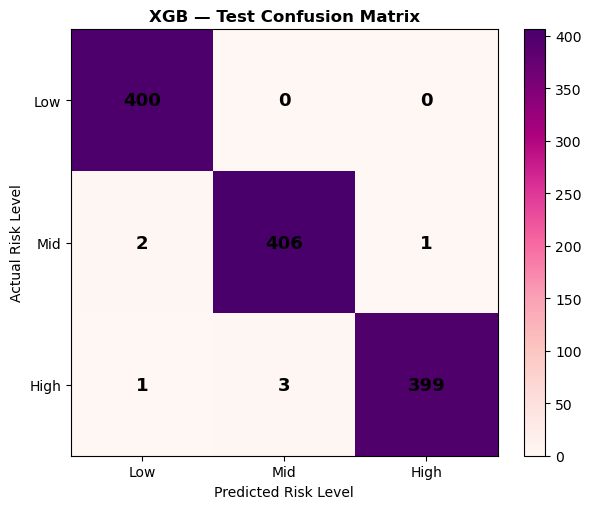

Classification Report:
              precision    recall  f1-score   support

         Low     0.9926    1.0000    0.9963       400
         Mid     0.9927    0.9927    0.9927       409
        High     0.9975    0.9901    0.9938       403

    accuracy                         0.9942      1212
   macro avg     0.9942    0.9942    0.9942      1212
weighted avg     0.9942    0.9942    0.9942      1212


Raw Confusion Matrix:
[[400   0   0]
 [  2 406   1]
 [  1   3 399]]


In [15]:

pred = test_predictions[selected_family]

cm = confusion_matrix(
    y_test,
    pred,
    labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(6.2, 5.2))

im = ax.imshow(
    cm,
    cmap="RdPu"
)

ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)

ax.set_xlabel("Predicted Risk Level")
ax.set_ylabel("Actual Risk Level")

ax.set_title(
    f"{selected_family} — Test Confusion Matrix",
    fontweight="bold"
)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold"
        )

plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "selected_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Classification Report:")
print(
    classification_report(
        y_test,
        pred,
        target_names=LABELS,
        digits=4,
        zero_division=0
    )
)

print("\nRaw Confusion Matrix:")
print(cm)


In [16]:

# Selected Full Model
full_model = final_models[selected_family]

# Default Basic CV
basic_default_folds = cross_validate_model(
    selected_family,
    features=BASIC,
    params=None
)

basic_default_stats = summarize_cv(
    basic_default_folds
)

# Optuna for Basic
basic_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEED
    )
)

def basic_objective(trial):
    params = suggest_params(
        trial, selected_family
    )

    fold_result = cross_validate_model(
        selected_family,
        features=BASIC,
        params=params
    )

    return float(
        summarize_cv(fold_result)["Macro_F1_Mean"]
    )

basic_study.optimize(
    basic_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

basic_tuned_folds = cross_validate_model(
    selected_family,
    features=BASIC,
    params=basic_study.best_trial.params
)

basic_tuned_stats = summarize_cv(
    basic_tuned_folds
)

if (
    basic_tuned_stats["Macro_F1_Mean"]
    > basic_default_stats["Macro_F1_Mean"] + 1e-10
):
    basic_params = basic_study.best_trial.params
    basic_cv = basic_tuned_folds
else:
    basic_params = None
    basic_cv = basic_default_folds

basic_model = build_model(
    selected_family,
    basic_params
)

basic_model.fit(
    train[BASIC],
    y_train
)

joblib.dump(
    basic_model,
    MODEL_DIR / "basic_model.joblib"
)

joblib.dump(
    full_model,
    MODEL_DIR / "full_model.joblib"
)

basic_stats = summarize_cv(basic_cv)
full_stats = summarize_cv(
    selected_cv_folds[selected_family]
)

basic_full_cv = pd.DataFrame([
    {
        "Feature_Set": "Basic (6)",
        **basic_stats
    },
    {
        "Feature_Set": "Full (8)",
        **full_stats
    }
])

display(basic_full_cv.round(5))

basic_full_cv.to_csv(
    RESULT_DIR / "basic_vs_full_cv.csv",
    index=False
)

model_metadata = {
    "selected_family": selected_family,
    "selection_rule": (
        "Training CV Macro-F1; "
        "High-Risk Recall within 0.005 margin"
    ),
    "labels": LABELS,
    "basic_features": BASIC,
    "full_features": FULL,
    "basic_params": basic_params,
    "full_params": selected_params[selected_family],
    "seed": SEED,
    "n_trials": N_TRIALS,
    "trained_on": "train.csv only"
}

with open(
    MODEL_DIR / "model_metadata.json",
    "w"
) as f:
    json.dump(model_metadata, f, indent=2)

print("BASIC AND FULL MODELS SAVED!")
print("Selected family:", selected_family)


  0%|          | 0/20 [00:00<?, ?it/s]

,Feature_Set,Macro_F1_Mean,Macro_F1_SD,High_Recall_Mean,High_Recall_SD
0,Basic (6),0.90560,0.01384,0.82295,0.03293
1,Full (8),0.99091,0.00398,0.98434,0.00936


BASIC AND FULL MODELS SAVED!
Selected family: XGB


In [17]:

basic_pred = basic_model.predict(
    data["test"][BASIC]
)

full_pred = full_model.predict(
    data["test"][FULL]
)

rows = []

for name, pred in [
    ("Basic (6)", basic_pred),
    ("Full (8)", full_pred)
]:
    rows.append({
        "Feature_Set": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro_F1": f1_score(
            y_test, pred, average="macro"
        ),
        "High_Recall": recall_score(
            y_test, pred,
            labels=[2],
            average="macro",
            zero_division=0
        ),
        "Ordinal_MAE": np.mean(
            np.abs(y_test - pred)
        )
    })

basic_full_test = pd.DataFrame(rows)

display(basic_full_test.round(5))

basic_full_test.to_csv(
    RESULT_DIR / "basic_vs_full_test.csv",
    index=False
)


,Feature_Set,Accuracy,Macro_F1,High_Recall,Ordinal_MAE
0,Basic (6),0.89521,0.89385,0.76923,0.11386
1,Full (8),0.99422,0.99423,0.99007,0.00660


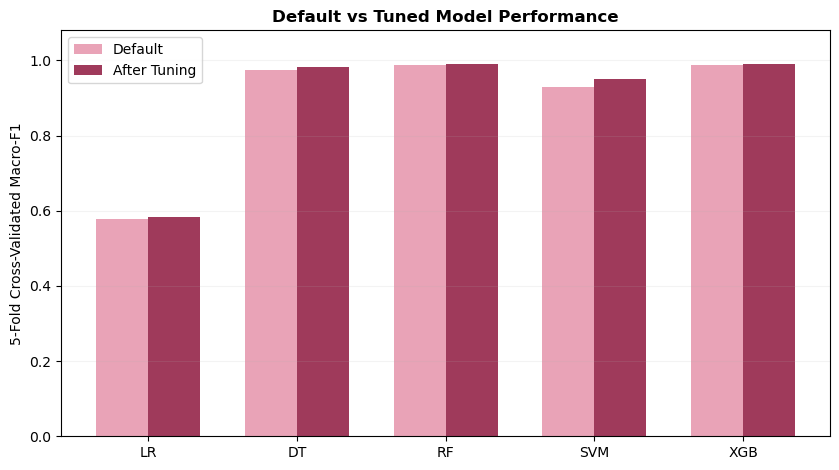

In [18]:

plot_df = tuning_df.set_index("Model").loc[FAMILIES]

x = np.arange(len(FAMILIES))
w = 0.35

fig, ax = plt.subplots(figsize=(8.5, 4.8))

ax.bar(
    x - w/2,
    plot_df["Default_Macro_F1"],
    width=w,
    label="Default",
    color="#E9A3B7"
)

ax.bar(
    x + w/2,
    plot_df["Tuned_Macro_F1"],
    width=w,
    label="After Tuning",
    color="#9F3A5B"
)

ax.set_xticks(x)
ax.set_xticklabels(FAMILIES)

ax.set_ylim(
    0,
    min(
        1.08,
        plot_df["Tuned_Macro_F1"].max() + 0.10
    )
)

ax.set_ylabel("5-Fold Cross-Validated Macro-F1")
ax.set_title(
    "Default vs Tuned Model Performance",
    fontweight="bold"
)

ax.legend()
ax.grid(axis="y", alpha=0.15)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "default_vs_tuned.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [19]:
from pathlib import Path
import joblib

basic = joblib.load(MODEL_DIR / "basic_model.joblib")
full = joblib.load(MODEL_DIR / "full_model.joblib")

print("Basic:", type(basic).__name__)
print("Full:", type(full).__name__)
print("Basic classes:", basic.classes_)
print("Full classes:", full.classes_)

assert list(basic.classes_) == [0, 1, 2]
assert list(full.classes_) == [0, 1, 2]

print("OFFICIAL MODELS READY FOR SECTION 4.2")

Basic: XGBClassifier
Full: XGBClassifier
Basic classes: [0 1 2]
Full classes: [0 1 2]
OFFICIAL MODELS READY FOR SECTION 4.2


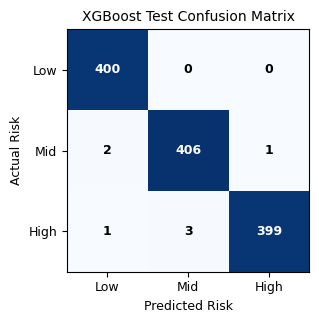

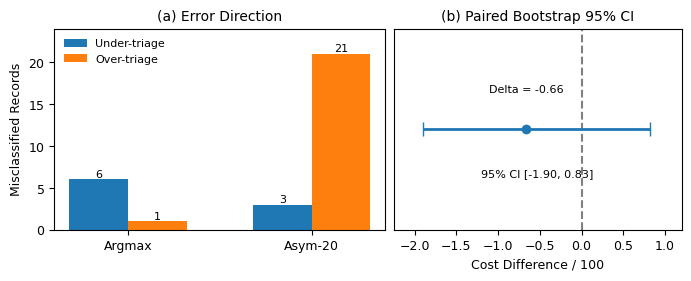

SAVED TO: /Users/hgianee/Downloads/Maternal health risk data 2/output/figures_final


In [1]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("figures_final")
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "savefig.dpi": 300
})

# FIGURE 2 — ACTUAL XGBOOST CONFUSION MATRIX
cm = np.array([
    [400, 0, 0],
    [2, 406, 1],
    [1, 3, 399]
])
labels = ["Low", "Mid", "High"]

fig, ax = plt.subplots(figsize=(4.3, 3.3))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=410)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            fontweight="bold",
            color="white" if cm[i, j] > 200 else "black"
        )

ax.set_xticks(range(3), labels)
ax.set_yticks(range(3), labels)
ax.set_xlabel("Predicted Risk")
ax.set_ylabel("Actual Risk")
ax.set_title("XGBoost Test Confusion Matrix")

fig.tight_layout()
fig.savefig(OUT / "figure_2_confusion_matrix.png",
            bbox_inches="tight")
plt.show()


# FIGURE 4 — COMPACT TWO-PANEL SEVERITY RESULTS
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(6.8, 2.7),
    gridspec_kw={"width_ratios": [1.15, 1]},
    layout="constrained"
)

# Panel (a): Under-triage vs Over-triage
x = np.arange(2)
w = 0.32

bars1 = ax1.bar(x - w/2, [6, 3], w, label="Under-triage")
bars2 = ax1.bar(x + w/2, [1, 21], w, label="Over-triage")

for b in list(bars1) + list(bars2):
    ax1.annotate(
        str(int(b.get_height())),
        (b.get_x() + b.get_width()/2, b.get_height()),
        ha="center", va="bottom", fontsize=8
    )

ax1.set_xticks(x, ["Argmax", "Asym-20"])
ax1.set_ylim(0, 24)
ax1.set_ylabel("Misclassified Records")
ax1.set_title("(a) Error Direction")
ax1.legend(frameon=False, fontsize=8)

# Panel (b): Actual bootstrap confidence interval
observed = -0.66007
ci_low = -1.89769
ci_high = 0.82508

ax2.axvline(0, linestyle="--", color="gray")

ax2.errorbar(
    observed, 0,
    xerr=[[observed - ci_low], [ci_high - observed]],
    fmt="o",
    capsize=5,
    linewidth=2
)

ax2.set_xlim(-2.25, 1.2)
ax2.set_ylim(-0.6, 0.6)
ax2.set_yticks([])
ax2.set_xlabel("Cost Difference / 100")
ax2.set_title("(b) Paired Bootstrap 95% CI")

ax2.text(observed, 0.22, "Delta = -0.66",
         ha="center", fontsize=8)

ax2.text(
    (ci_low + ci_high)/2, -0.28,
    "95% CI [-1.90, 0.83]",
    ha="center", fontsize=8
)

fig.savefig(
    OUT / "figure_4_severity_two_panels.png",
    bbox_inches="tight"
)
plt.show()

print("SAVED TO:", OUT.resolve())


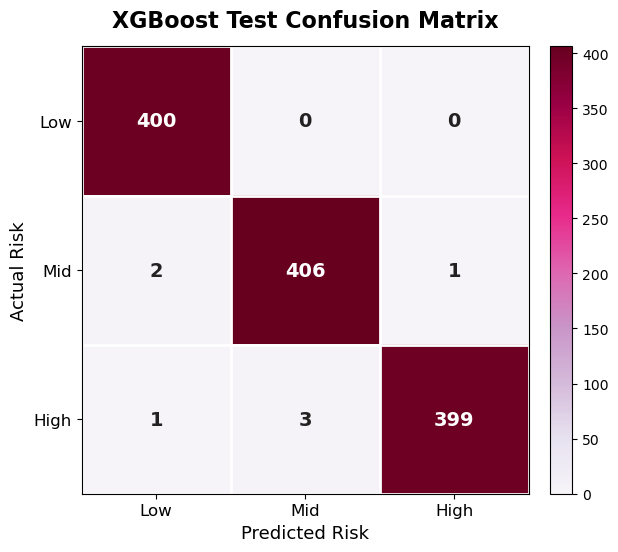

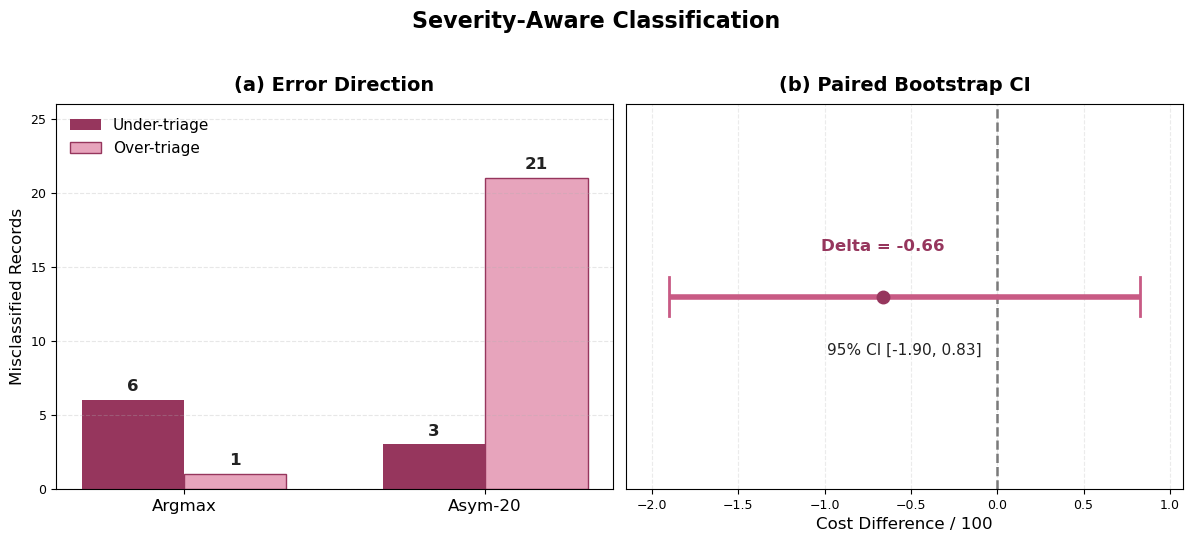

Saved files in: /Users/hgianee/Downloads/Maternal health risk data 2/output/figures_final


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

# =========================
# OUTPUT FOLDER
# =========================
OUT_DIR = "figures_final"
os.makedirs(OUT_DIR, exist_ok=True)

# =========================
# PINK THEME
# =========================
PINK_DARK = "#96365D"
PINK_MAIN = "#C85A84"
PINK_LIGHT = "#E7A4BC"
PINK_PALE = "#F6D7E2"
GREY = "#7A7A7A"
BLACK = "#222222"

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "regular"


# ============================================================
# FIGURE 2: XGBOOST TEST CONFUSION MATRIX
# ============================================================
cm = np.array([
    [400, 0,   0],
    [2,   406, 1],
    [1,   3,   399]
])

labels = ["Low", "Mid", "High"]

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(cm, cmap="PuRd")

# ticks
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, fontsize=12)
ax.set_yticklabels(labels, fontsize=12)

# labels and title
ax.set_xlabel("Predicted Risk", fontsize=13)
ax.set_ylabel("Actual Risk", fontsize=13)
ax.set_title("XGBoost Test Confusion Matrix", fontsize=16, pad=14)

# grid lines
ax.set_xticks(np.arange(-.5, len(labels), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(labels), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

# annotate cells
max_val = cm.max()
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        color = "white" if val > max_val * 0.45 else BLACK
        ax.text(j, i, f"{val}", ha="center", va="center",
                fontsize=14, fontweight="bold", color=color)

# colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

fig.savefig(os.path.join(OUT_DIR, "figure_2_confusion_matrix_pink.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "figure_2_confusion_matrix_pink.pdf"), bbox_inches="tight")
plt.show()


# ============================================================
# FIGURE 4: SEVERITY-AWARE CLASSIFICATION (2 PANELS)
# Panel (a): Under-triage vs Over-triage
# Panel (b): Paired bootstrap CI
# ============================================================

# Data
policies = ["Argmax", "Asym-20"]
undertriage = [6, 3]
overtriage = [1, 21]

delta = -0.66007
ci_low = -1.89769
ci_high = 0.82508

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

# -------------------------
# Panel (a): Error direction
# -------------------------
ax = axes[0]
x = np.arange(len(policies))
width = 0.34

bars1 = ax.bar(x - width/2, undertriage, width,
               label="Under-triage", color=PINK_DARK)
bars2 = ax.bar(x + width/2, overtriage, width,
               label="Over-triage", color=PINK_LIGHT, edgecolor=PINK_DARK)

ax.set_xticks(x)
ax.set_xticklabels(policies, fontsize=12)
ax.set_ylabel("Misclassified Records", fontsize=12)
ax.set_title("(a) Error Direction", fontsize=14, pad=10)
ax.legend(frameon=False, fontsize=11)
ax.set_ylim(0, max(overtriage) + 5)
ax.grid(axis="y", linestyle="--", alpha=0.3)

# add labels
for bars in [bars1, bars2]:
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.4, f"{int(h)}",
                ha="center", va="bottom", fontsize=12, fontweight="bold", color=BLACK)

# -------------------------
# Panel (b): Bootstrap CI
# -------------------------
ax = axes[1]

# zero line
ax.axvline(0, color=GREY, linestyle="--", linewidth=1.8)

# CI line
ax.hlines(y=0, xmin=ci_low, xmax=ci_high, color=PINK_MAIN, linewidth=4)
ax.plot(delta, 0, 'o', color=PINK_DARK, markersize=9)

# end caps
ax.plot([ci_low, ci_low], [-0.05, 0.05], color=PINK_MAIN, linewidth=2)
ax.plot([ci_high, ci_high], [-0.05, 0.05], color=PINK_MAIN, linewidth=2)

ax.set_title("(b) Paired Bootstrap CI", fontsize=14, pad=10)
ax.set_xlabel("Cost Difference / 100", fontsize=12)
ax.set_yticks([])
ax.set_ylim(-0.5, 0.5)
ax.grid(axis="x", linestyle="--", alpha=0.25)

# Make x-limits a bit wider than CI
margin = 0.25
ax.set_xlim(ci_low - margin, ci_high + margin)

# text annotations
ax.text(delta, 0.12, f"Delta = {delta:.2f}", ha="center",
        fontsize=12, fontweight="bold", color=PINK_DARK)
ax.text((ci_low + ci_high)/2, -0.15,
        f"95% CI [{ci_low:.2f}, {ci_high:.2f}]",
        ha="center", fontsize=11, color=BLACK)

fig.suptitle("Severity-Aware Classification", fontsize=16, fontweight="bold", y=1.03)
plt.tight_layout()

fig.savefig(os.path.join(OUT_DIR, "figure_4_severity_two_panels_pink.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, "figure_4_severity_two_panels_pink.pdf"), bbox_inches="tight")
plt.show()

print("Saved files in:", os.path.abspath(OUT_DIR))

In [3]:

from pathlib import Path
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, recall_score

def find_csv(name):
    bases = [
        Path.cwd(),
        Path.cwd() / "output",
        Path.cwd().parent,
        Path.cwd().parent / "output"
    ]
    for base in bases:
        path = base / name
        if path.is_file():
            return path
    raise FileNotFoundError(f"Cannot find {name}")

data = pd.read_csv(find_csv("model_ready.csv"))
splits = pd.read_csv(find_csv("split_assignments.csv"))
folds = pd.read_csv(find_csv("train_cv_folds.csv"))

# Use ONLY training records for this exploratory test
df = (
    data.merge(splits, on="row_id", validate="one_to_one")
        .query("split == 'train'")
        .merge(folds, on="row_id", validate="one_to_one")
)

features = [
    "Age", "BodyTemp", "HeartRate",
    "SystolicBP", "DiastolicBP", "BMI",
    "HbA1c", "FastingGlucose"
]

feature_sets = {
    "Full (8)": features,
    "Without Temperature (7)": [
        c for c in features if c != "BodyTemp"
    ],
    "Basic (6)": features[:6],
    "Temperature Only (1)": ["BodyTemp"]
}

label_map = {"Low": 0, "Mid": 1, "High": 2}
y = df["RiskLevel"].map(label_map).to_numpy()

assert not pd.isna(y).any()
assert len(df) == 3634
assert df["cv_fold"].nunique() == 5

results = []

for name, cols in feature_sets.items():
    scores = []
    recalls = []

    for fold_id in sorted(df["cv_fold"].unique()):
        train_mask = df["cv_fold"] != fold_id
        valid_mask = ~train_mask

        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=42,
            n_jobs=2,
            tree_method="hist",
            eval_metric="mlogloss"
        )

        model.fit(df.loc[train_mask, cols],
                  y[train_mask.to_numpy()])

        pred = model.predict(df.loc[valid_mask, cols])
        actual = y[valid_mask.to_numpy()]

        scores.append(f1_score(
            actual, pred, average="macro"
        ))
        recalls.append(recall_score(
            actual, pred,
            labels=[2],
            average="macro"
        ))

    results.append({
        "Feature_Set": name,
        "Macro_F1_Mean": np.mean(scores),
        "Macro_F1_SD": np.std(scores, ddof=1),
        "High_Recall_Mean": np.mean(recalls)
    })

result_df = pd.DataFrame(results)
display(result_df.round(5))

result_df.to_csv(
    "exploratory_feature_ablation_cv.csv",
    index=False
)


,Feature_Set,Macro_F1_Mean,Macro_F1_SD,High_Recall_Mean
0,Full (8),0.98816,0.00531,0.98190
1,Without Temperature (7),0.98678,0.00565,0.97778
2,Basic (6),0.88585,0.01378,0.82045
3,Temperature Only (1),0.50186,0.02269,0.71735


In [5]:

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize
import numpy as np
import pandas as pd

P = np.asarray(P_cal)
y = np.asarray(y_test).astype(int)

assert P.shape == (len(y), 3)
assert np.allclose(P.sum(axis=1), 1, atol=1e-6)

y_bin = label_binarize(y, classes=[0, 1, 2])

rows = []

for k, label in enumerate(["Low", "Mid", "High"]):
    rows.append({
        "Class": label,
        "ROC_AUC": roc_auc_score(y_bin[:, k], P[:, k]),
        "Average_Precision": average_precision_score(
            y_bin[:, k], P[:, k]
        )
    })

rows.append({
    "Class": "Macro Average",
    "ROC_AUC": roc_auc_score(
        y, P, multi_class="ovr", average="macro",
        labels=[0, 1, 2]
    ),
    "Average_Precision": np.mean([
        r["Average_Precision"] for r in rows
    ])
})
from pathlib import Path
import numpy as np
import pandas as pd

cwd = Path.cwd()

candidates = []
for base in [cwd, cwd.parent, cwd.parent.parent]:
    candidates.extend([
        base / "section_4_4" / "adaptive_test_B100.csv",
        base / "output" / "section_4_4" / "adaptive_test_B100.csv",
        base / "adaptive_test_B100.csv",
    ])

found = next((p for p in candidates if p.is_file()), None)

if found is None:
    print("Current folder:", cwd)
    raise FileNotFoundError(
        "Chưa tìm thấy adaptive_test_B100.csv. "
        "Hãy kiểm tra thư mục output/section_4_4."
    )

df = pd.read_csv(found)

print("File:", found.resolve())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())
display(pd.DataFrame(rows).round(4))


NameError: name 'P_cal' is not defined

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd

cwd = Path.cwd()

candidates = []
for base in [cwd, cwd.parent, cwd.parent.parent]:
    candidates.extend([
        base / "section_4_4" / "adaptive_test_B100.csv",
        base / "output" / "section_4_4" / "adaptive_test_B100.csv",
        base / "adaptive_test_B100.csv",
    ])

found = next((p for p in candidates if p.is_file()), None)

if found is None:
    print("Current folder:", cwd)
    raise FileNotFoundError(
        "Chưa tìm thấy adaptive_test_B100.csv. "
        "Hãy kiểm tra thư mục output/section_4_4."
    )

df = pd.read_csv(found)

print("File:", found.resolve())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

File: /Users/hgianee/Downloads/Maternal health risk data 2/output/section_4_4/adaptive_test_B100.csv
Shape: (1212, 11)
Columns: ['row_id', 'RiskLevel', 'Budget', 'Strategy', 'Selected_For_Measurement', 'Basic_Selection_Score', 'Basic_Entropy', 'p_Low', 'p_Mid', 'p_High', 'Prediction_Argmax']


,row_id,RiskLevel,Budget,Strategy,Selected_For_Measurement,Basic_Selection_Score,Basic_Entropy,p_Low,p_Mid,p_High,Prediction_Argmax
0,R000001,High,100,Uncertainty,True,0.000498,0.000498,0.000076,0.000349,0.999575,High
1,R000005,High,100,Uncertainty,True,0.001958,0.001958,0.000049,0.000448,0.999504,High
2,R000006,High,100,Uncertainty,True,0.051298,0.051298,0.000164,0.024031,0.975805,High
3,R000009,High,100,Uncertainty,True,0.006910,0.006910,0.000527,0.124583,0.874890,High
4,R000010,High,100,Uncertainty,True,0.000380,0.000380,0.000087,0.000253,0.999659,High


In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Tự nhận diện các cột xác suất
def normalize_name(s):
    return "".join(c for c in str(s).lower() if c.isalnum())

normalized = {normalize_name(c): c for c in df.columns}

def find_prob(label):
    for prefix in ["p", "prob", "probability"]:
        key = prefix + label.lower()
        if key in normalized:
            return normalized[key]
    raise ValueError(
        f"Không tìm thấy cột xác suất {label}. "
        f"Columns: {df.columns.tolist()}"
    )

prob_cols = [
    find_prob("Low"),
    find_prob("Mid"),
    find_prob("High")
]

assert "RiskLevel" in df.columns, "Thiếu RiskLevel"

P = df[prob_cols].to_numpy(dtype=float)

label_map = {"low": 0, "mid": 1, "high": 2}
y = (
    df["RiskLevel"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(label_map)
    .to_numpy()
)

assert len(df) == 1212, "Không đúng Test set!"
assert not np.isnan(y).any(), "Có nhãn chưa được nhận diện"
assert np.isfinite(P).all(), "Xác suất chứa NaN/Inf"
assert np.all((P >= 0) & (P <= 1))
assert np.allclose(P.sum(axis=1), 1, atol=1e-5)

y = y.astype(int)
pred = P.argmax(axis=1)

print("Accuracy:", round((pred == y).mean(), 5))
print("High Risk records:", np.sum(y == 2))

# Kiểm tra khớp Section 4.2
assert np.sum(pred == y) == 1205
assert np.sum((pred == 2) & (y == 2)) == 399

# ROC-AUC and Average Precision
rows = []

for k, label in enumerate(["Low", "Mid", "High"]):
    binary_true = (y == k).astype(int)

    rows.append({
        "Class": label,
        "ROC_AUC": roc_auc_score(binary_true, P[:, k]),
        "Average_Precision": average_precision_score(
            binary_true, P[:, k]
        )
    })

rows.append({
    "Class": "Macro Average",
    "ROC_AUC": roc_auc_score(
        y, P, multi_class="ovr",
        average="macro", labels=[0, 1, 2]
    ),
    "Average_Precision": np.mean([
        r["Average_Precision"] for r in rows
    ])
})

auc_table = pd.DataFrame(rows)

print("\nROC-AUC AND AVERAGE PRECISION")
display(auc_table.round(5))

auc_table.to_csv("additional_roc_auc.csv", index=False)

# SOFT OUTPUT EXAMPLES
entropy = -np.sum(
    np.clip(P, 1e-12, 1) *
    np.log(np.clip(P, 1e-12, 1)),
    axis=1
) / np.log(3)

correct = np.where(pred == y)[0]
undertriage = np.where((y == 2) & (pred < 2))[0]

chosen = []

# 1. Very confident correct prediction
chosen.append(("Confident correct", correct[np.argmin(entropy[correct])]))

# 2. Most uncertain different observation
uncertain_order = np.argsort(-entropy)
idx = next(i for i in uncertain_order if i not in [x[1] for x in chosen])
chosen.append(("High uncertainty", idx))

# 3. High-risk under-triage, prefer High -> Low
severe = np.where((y == 2) & (pred == 0))[0]
pool = severe if len(severe) else undertriage

if len(pool):
    idx = next((i for i in pool if i not in [x[1] for x in chosen]), pool[0])
    chosen.append(("Under-triage", idx))

labels = np.array(["Low", "Mid", "High"])
examples = []

for name, i in chosen:
    examples.append({
        "Case": name,
        "row_id": df["row_id"].iloc[i] if "row_id" in df.columns else i,
        "P(Low)": P[i, 0],
        "P(Mid)": P[i, 1],
        "P(High)": P[i, 2],
        "Predicted": labels[pred[i]],
        "Actual": labels[y[i]],
        "Entropy": entropy[i]
    })

examples_df = pd.DataFrame(examples)

print("\nSOFT OUTPUT EXAMPLES")
display(examples_df.round(5))

examples_df.to_csv(
    "additional_soft_output_examples.csv",
    index=False
)

print("\nALL ADDITIONAL ANALYSES COMPLETED!")

Accuracy: 0.99422
High Risk records: 403

ROC-AUC AND AVERAGE PRECISION


,Class,ROC_AUC,Average_Precision
0,Low,0.99996,0.99991
1,Mid,0.99929,0.99853
2,High,0.99966,0.99945
3,Macro Average,0.99964,0.99930



SOFT OUTPUT EXAMPLES


,Case,row_id,P(Low),P(Mid),P(High),Predicted,Actual,Entropy
0,Confident correct,R005794,0.00000,0.00001,0.99999,High,High,0.00015
1,High uncertainty,R001727,0.35033,0.61816,0.03151,Mid,Mid,0.70428
2,Under-triage,R003661,0.57036,0.00241,0.42723,Low,High,0.63545



ALL ADDITIONAL ANALYSES COMPLETED!
